# Visualize Layer-Averaged Graph-Spectral Diagnostics for Natural-Language and Code Inputs

This Visualize notebook loads cached layer-averaged graph-spectral diagnostics and compares natural-language and code inputs with the main numerical input families across context lengths using Llama-3.2-3B, as presented under **Preliminary Graph-Spectral Comparison of Numerical, Natural-Language, and Code Inputs** in the appendix.

Each diagnostic is displayed in three panels: content-aligned United Nations translations across six languages, programming-language inputs, and English texts across domains. The same numerical families appear as dashed or dash-dotted references at matching context lengths in every panel. Curves and shaded bands show the mean and $\pm 1$ standard deviation across 50 samples per natural-language or code family and 20 realizations per numerical family, after averaging each diagnostic over the model's 28 layers.

The diagnostics measure effective spectral support, $\exp(\mathrm{SE})$; the normalized Fiedler value, $\lambda_2$; and the high-frequency energy ratio (HFER). Lower Fiedler values indicate weaker global attention connectivity, higher HFER indicates a larger high-frequency share of hidden-state energy, and larger effective spectral support indicates a broader distribution of that energy across graph Fourier modes.

The notebook loads all four datasets from `cache/`. The Generate notebooks under `Data-generation/` save final language and code results to this shared cache. The numerical reference is copied from the layer-averaged results under `Main/Graph-spectral-diagnostics/`.


Set imports, panel configuration, display options, and relative data paths.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

SOURCE_CONFIGS = [
    {
        "source": "MultiUN languages",
        "panel_title": "United Nations Texts Across Languages",
        "cache_filename": "multiun_language_all_metrics_averaged_over_layers_vs_context_length.npz",
        "legend_title": "Translation language",
    },
    {
        "source": "Programming languages",
        "panel_title": "Programming Languages",
        "cache_filename": "programming_language_all_metrics_averaged_over_layers_vs_context_length.npz",
        "legend_title": "Programming input",
    },
    {
        "source": "Natural-language corpora",
        "panel_title": "English Texts Across Domains",
        "cache_filename": "natural_language_all_metrics_averaged_over_layers_vs_context_length.npz",
        "legend_title": "Natural-language input",
    },
]

INCLUDE_NUMERICAL_BASELINE = True
SHOW_STD_BANDS = True
SAVE_FIGURES = True
FIGURE_DIR_NAME = "figures"

CACHE_DIR = Path("cache")
FIGURE_DIR = Path(FIGURE_DIR_NAME)


Define input labels, plotting styles, and helpers for loading cached layer-averaged diagnostics.


In [2]:
# Expand cache identifiers into labels for the panel legends
DISPLAY_NAME_OVERRIDES = {
    "ar": "Arabic",
    "zh": "Chinese",
    "en": "English",
    "fr": "French",
    "ru": "Russian",
    "es": "Spanish",
    "python": "Python",
    "javascript": "JavaScript",
    "java": "Java",
    "cpp": "C++",
    "go": "Go",
    "rust": "Rust",
    "news": "News",
    "fiction": "Fiction",
    "wiki": "Wiki",
    "arxiv": "arXiv",
    "dialogue": "Dialogue",
    "legal": "Legal",
}

OKABE_ITO_COLORS = {
    "orange": "#E69F00",
    "sky_blue": "#56B4E9",
    "bluish_green": "#009E73",
    "yellow": "#F0E442",
    "blue": "#0072B2",
    "vermillion": "#D55E00",
    "reddish_purple": "#CC79A7",
    "black": "#000000",
}
PANEL_COLOR_SEQUENCE = [
    OKABE_ITO_COLORS[name]
    for name in ["blue", "vermillion", "bluish_green", "reddish_purple", "orange", "sky_blue"]
]
PANEL_MARKERS = ["o", "s", "D", "^", "v", "P"]

NUMERICAL_DISPLAY = {
    "Constant sampled": "Constant",
    "Logistic r=3.2": "Period 2",
    "Logistic r=3.5": "Period 4",
    "Logistic r=3.55": "Period 8",
    "Logistic r=3.566": "Period 16",
    "Logistic r=3.5692": "Period 32",
    "Logistic r=3.5698": "Period 64",
    "Logistic r=3.9": "Logistic r=3.9",
    "Logistic r=4.0": "Logistic r=4.0",
    "Lorenz": "Lorenz",
}

NUMERICAL_STYLES = {
    "Constant sampled": dict(color="#7f7f7f", linestyle="--", marker="o", linewidth=1.75),
    "Logistic r=3.2": dict(color="#C2BBB2", linestyle="--", marker="s", linewidth=1.65),
    "Logistic r=3.5": dict(color="#B1A89D", linestyle="--", marker="D", linewidth=1.65),
    "Logistic r=3.55": dict(color="#A39A8F", linestyle="--", marker="^", linewidth=1.65),
    "Logistic r=3.566": dict(color="#91877C", linestyle="--", marker="v", linewidth=1.65),
    "Logistic r=3.5692": dict(color="#7F756A", linestyle="--", marker="P", linewidth=1.75),
    "Logistic r=3.5698": dict(color="#6C6258", linestyle="--", marker="X", linewidth=1.75),
    "Logistic r=3.9": dict(color="#B65A50", linestyle="-.", marker="o", linewidth=1.9),
    "Logistic r=4.0": dict(color="#9E3F3F", linestyle="-.", marker="s", linewidth=1.9),
    "Lorenz": dict(color="#5C1E2B", linestyle="-.", marker="D", linewidth=2.05),
}


def display_name(name):
    name = str(name)
    return DISPLAY_NAME_OVERRIDES.get(name, name.replace("_", " ").title())


def scalar(data, key):
    value = data[key]
    return value.item() if getattr(value, "ndim", 0) == 0 else value


def load_layer_averaged_cache(path, source):
    # Read cached means and standard deviations
    path = Path(path)
    with np.load(path, allow_pickle=False) as data:
        cache = {
            "path": path,
            "source": source,
            "input_names": data["input_names"].astype(str),
            "context_token_counts": data["context_token_counts"].astype(int),
            "run_ids": data["run_ids"].astype(int) if "run_ids" in data.files else np.array([], dtype=int),
            "num_ensemble_runs": int(scalar(data, "num_ensemble_runs")),
            "num_layers": int(scalar(data, "num_layers")),
            "model_name": str(scalar(data, "model_name")),
            "active_modes_mean": data["active_modes_mean"].astype(float),
            "active_modes_std": data["active_modes_std"].astype(float),
            "fiedler_mean": data["fiedler_mean"].astype(float),
            "fiedler_std": data["fiedler_std"].astype(float),
            "hfer_mean": data["hfer_mean"].astype(float),
            "hfer_std": data["hfer_std"].astype(float),
        }
        for key in ["language_codes", "language_names", "family_condition_types"]:
            if key in data.files:
                cache[key] = data[key].astype(str)
    return cache


def input_labels(cache):
    if "language_names" in cache and len(cache["language_names"]) == len(cache["input_names"]):
        return [str(name) for name in cache["language_names"]]
    return [display_name(name) for name in cache["input_names"]]


def panel_input_style(input_idx):
    # Draw language and code curves above the numerical references
    return dict(
        color=PANEL_COLOR_SEQUENCE[input_idx % len(PANEL_COLOR_SEQUENCE)],
        marker=PANEL_MARKERS[input_idx % len(PANEL_MARKERS)],
        linestyle="-",
        linewidth=2.25,
        markersize=4.62,
        zorder=5,
    )


def numerical_style(input_idx, name):
    style = dict(NUMERICAL_STYLES.get(str(name), {}))
    if not style:
        style = dict(
            color=plt.get_cmap("tab20")(6 + input_idx),
            linestyle="--",
            marker=PANEL_MARKERS[input_idx % len(PANEL_MARKERS)],
            linewidth=1.7,
        )
    style.setdefault("markersize", 3.74)
    style.setdefault("zorder", 2)
    return style


def numerical_label(name):
    name = str(name)
    return NUMERICAL_DISPLAY.get(name, name)


Load the language, code, and numerical caches and verify matching context lengths, layer counts, and model names.


In [3]:
# Load one cache per panel in the configured order
domain_caches = []
for cfg in SOURCE_CONFIGS:
    cache_path = CACHE_DIR / cfg["cache_filename"]
    if not cache_path.exists():
        raise FileNotFoundError(f"Missing cache for {cfg['source']}: {cache_path}")
    cache = load_layer_averaged_cache(cache_path, cfg["source"])
    cache.update(cfg)
    domain_caches.append(cache)

# Require matching context lengths, layer counts, and model names
reference = domain_caches[0]
for cache in domain_caches[1:]:
    if not np.array_equal(cache["context_token_counts"], reference["context_token_counts"]):
        raise ValueError(f"Context token counts differ for {cache['source']}.")
    if cache["num_layers"] != reference["num_layers"]:
        raise ValueError(f"Layer counts differ for {cache['source']}.")
    if cache["model_name"] != reference["model_name"]:
        raise ValueError(f"Model names differ for {cache['source']}.")

# Load the shared numerical references and check the same alignment
numerical_cache = None
if INCLUDE_NUMERICAL_BASELINE:
    numerical_path = CACHE_DIR / "all_metrics_averaged_over_layers_vs_context_length.npz"
    if not numerical_path.exists():
        raise FileNotFoundError(f"Missing numerical baseline cache: {numerical_path}")
    numerical_cache = load_layer_averaged_cache(numerical_path, "Numerical baseline")
    if not np.array_equal(numerical_cache["context_token_counts"], reference["context_token_counts"]):
        raise ValueError("Numerical baseline context token counts differ from the language caches.")
    if numerical_cache["num_layers"] != reference["num_layers"]:
        raise ValueError("Numerical baseline layer count differs from the language caches.")
    if numerical_cache["model_name"] != reference["model_name"]:
        raise ValueError("Numerical baseline model differs from the language caches.")

context_token_counts = reference["context_token_counts"].astype(float)


Define the shared three-panel layout, standard-deviation bands, legends, and PDF export.


In [4]:
METRIC_SPECS = {
    "active_modes": {
        "ylabel": r"$\exp(\mathrm{SE})$",
        "ytick_format": "{x:.0f}",
        "filename": "active-modes-language-inputs.pdf",
    },
    "fiedler": {
        "ylabel": r"$\lambda_2$",
        "ytick_format": "{x:.2f}",
        "filename": "fiedler-language-inputs.pdf",
    },
    "hfer": {
        "ylabel": "HFER",
        "ytick_format": "{x:.2f}",
        "filename": "hfer-language-inputs.pdf",
    },
}


def metric_limits(metric_name):
    arrays = []
    for cache in domain_caches:
        arrays.append(cache[f"{metric_name}_mean"])
        if SHOW_STD_BANDS:
            arrays.extend([
                cache[f"{metric_name}_mean"] - cache[f"{metric_name}_std"],
                cache[f"{metric_name}_mean"] + cache[f"{metric_name}_std"],
            ])
    if numerical_cache is not None:
        arrays.append(numerical_cache[f"{metric_name}_mean"])
        if SHOW_STD_BANDS:
            arrays.extend([
                numerical_cache[f"{metric_name}_mean"] - numerical_cache[f"{metric_name}_std"],
                numerical_cache[f"{metric_name}_mean"] + numerical_cache[f"{metric_name}_std"],
            ])
    values = np.concatenate([np.ravel(arr[np.isfinite(arr)]) for arr in arrays])
    ymin, ymax = float(values.min()), float(values.max())
    pad = 0.06 * (ymax - ymin) if ymax > ymin else 1.0
    return ymin - pad, ymax + pad


def format_panel_axis(ax, ylabel, panel_title, ytick_format, show_ylabel):
    # Use the same context axis and formatting for each input group
    max_context = int(np.max(context_token_counts))
    ax.set_xticks([500, 1000, 1500, 2000])
    ax.set_xlim(0, max_context * 1.04)
    ax.set_xlabel("Context length (tokens)", fontsize=16.8)
    ax.set_ylabel(ylabel if show_ylabel else "", fontsize=18.48)
    ax.set_title(panel_title, fontsize=19.8)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(StrMethodFormatter(ytick_format))
    ax.tick_params(axis="both", labelsize=14.76)
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", alpha=0.18, linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def maybe_save(fig, filename):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / filename, bbox_inches="tight", dpi=300)


def build_numerical_handles():
    # Build one shared legend for the numerical curves repeated in every panel
    if numerical_cache is None:
        return []
    handles = []
    for idx, name in enumerate(numerical_cache["input_names"]):
        style = numerical_style(idx, name)
        handles.append(
            Line2D(
                [0],
                [0],
                label=numerical_label(name),
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=style["linewidth"],
                markersize=style.get("markersize", 3.4),
            )
        )
    return handles


def add_domain_legend_dividers(fig, axes):
    y0, y1 = 0.178, 0.228
    for divider_idx, (left_ax, right_ax) in enumerate(zip(axes[:-1], axes[1:])):
        left_box = left_ax.get_position()
        right_box = right_ax.get_position()
        x = 0.5 * (left_box.x1 + right_box.x0)
        if divider_idx == 0:
            x += 0.014
        fig.add_artist(
            Line2D(
                [x, x],
                [y0, y1],
                transform=fig.transFigure,
                color="#B8B8B8",
                linewidth=1.3,
                alpha=0.8,
                clip_on=False,
            )
        )


def plot_three_panel_metric(metric_name):
    spec = METRIC_SPECS[metric_name]
    fig, axes = plt.subplots(1, 3, figsize=(21.0, 7.6), dpi=200, sharey=True)
    y_limits = metric_limits(metric_name)

    for ax_idx, (ax, cache) in enumerate(zip(axes, domain_caches)):
        x = cache["context_token_counts"].astype(float)

        # Repeat the matched-context numerical means and standard-deviation bands
        if numerical_cache is not None:
            for num_idx, num_name in enumerate(numerical_cache["input_names"]):
                y = numerical_cache[f"{metric_name}_mean"][num_idx].astype(float)
                band = numerical_cache[f"{metric_name}_std"][num_idx].astype(float)
                style = numerical_style(num_idx, num_name)
                ax.plot(x, y, **style)
                if SHOW_STD_BANDS:
                    ax.fill_between(
                        x,
                        y - band,
                        y + band,
                        color=style["color"],
                        alpha=0.075,
                        linewidth=0,
                        zorder=max(style.get("zorder", 2) - 0.5, 0),
                    )

        # Overlay the six language or code families using cached summary statistics
        domain_handles = []
        labels = input_labels(cache)
        for input_idx, (input_name, label) in enumerate(zip(cache["input_names"], labels)):
            y = cache[f"{metric_name}_mean"][input_idx].astype(float)
            band = cache[f"{metric_name}_std"][input_idx].astype(float)
            style = panel_input_style(input_idx)
            curve_label = label
            line, = ax.plot(x, y, label=curve_label, **style)
            domain_handles.append(line)
            if SHOW_STD_BANDS:
                ax.fill_between(
                    x,
                    y - band,
                    y + band,
                    color=style["color"],
                    alpha=0.075,
                    linewidth=0,
                    zorder=max(style.get("zorder", 5) - 0.5, 0),
                )

        ax.set_ylim(*y_limits)
        format_panel_axis(
            ax,
            spec["ylabel"],
            cache["panel_title"],
            spec["ytick_format"],
            show_ylabel=(ax_idx == 0),
        )
        # Give each panel its own input legend, using markers for compact labels
        domain_legend = ax.legend(
            handles=domain_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.16),
            ncol=len(domain_handles),
            frameon=False,
            fontsize=16.668,
            handlelength=0.85,
            handletextpad=0.22,
            columnspacing=0.35,
            markerscale=1.8,
        )
        for legend_line in domain_legend.get_lines():
            legend_line.set_linestyle("None")
            legend_line.set_markersize(8.0)

    # Place the shared numerical legend below the three panel legends
    numerical_handles = build_numerical_handles()
    if numerical_handles:
        numerical_legend = fig.legend(
            handles=numerical_handles,
            loc="lower center",
            bbox_to_anchor=(0.07, 0.12, 0.86, 0.035),
            ncol=len(numerical_handles),
            frameon=False,
            fontsize=16.392,
            handlelength=2.1,
            handletextpad=0.5,
            columnspacing=3.4,
            markerscale=2.0,
            mode="expand",
            borderaxespad=0.0,
        )
        for legend_line in numerical_legend.get_lines():
            legend_line.set_linewidth(2.8)
    
    fig.subplots_adjust(left=0.065, right=0.99, top=0.895, bottom=0.33, wspace=0.16)
    add_domain_legend_dividers(fig, axes)
    maybe_save(fig, spec["filename"])
    fig.set_dpi(150)
    plt.show()

Plot effective spectral support, $\exp(\mathrm{SE})$, across context lengths.


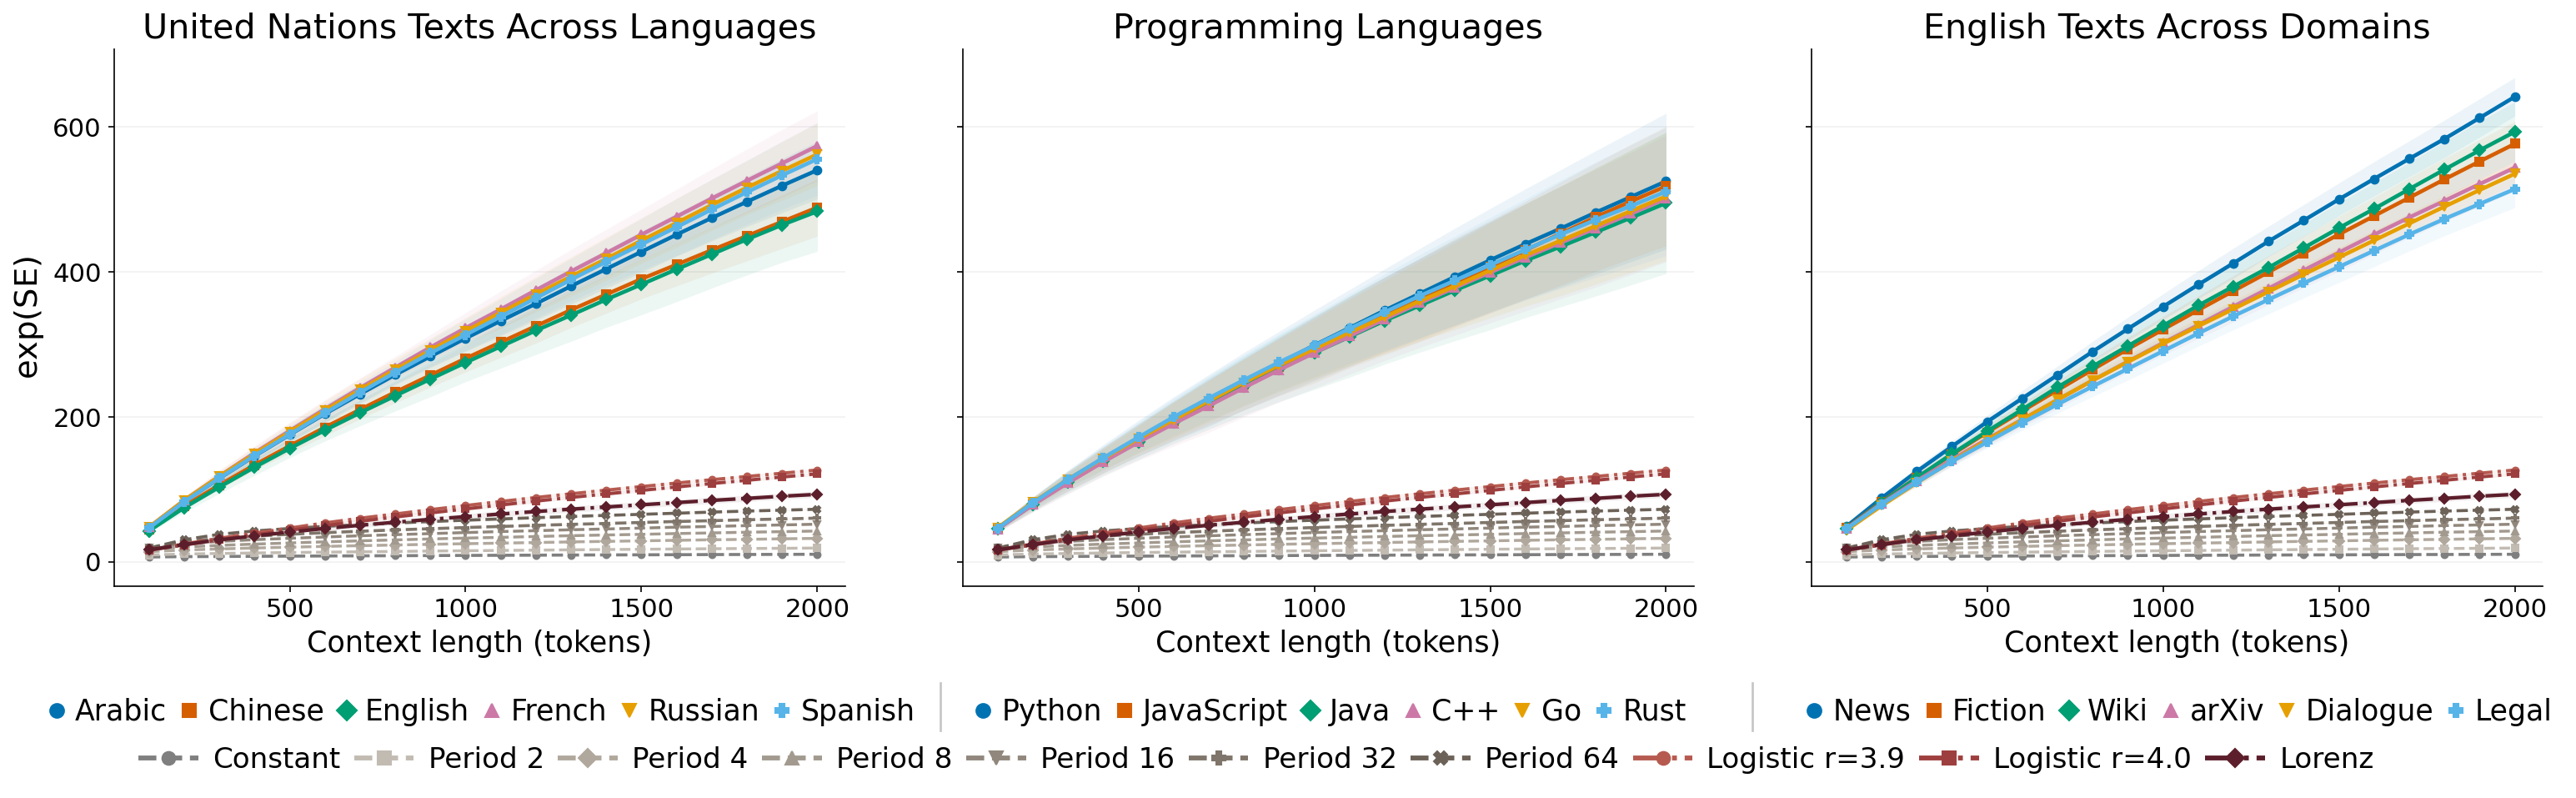

In [5]:
plot_three_panel_metric("active_modes")

Plot normalized Fiedler values, $\lambda_2$, across context lengths.


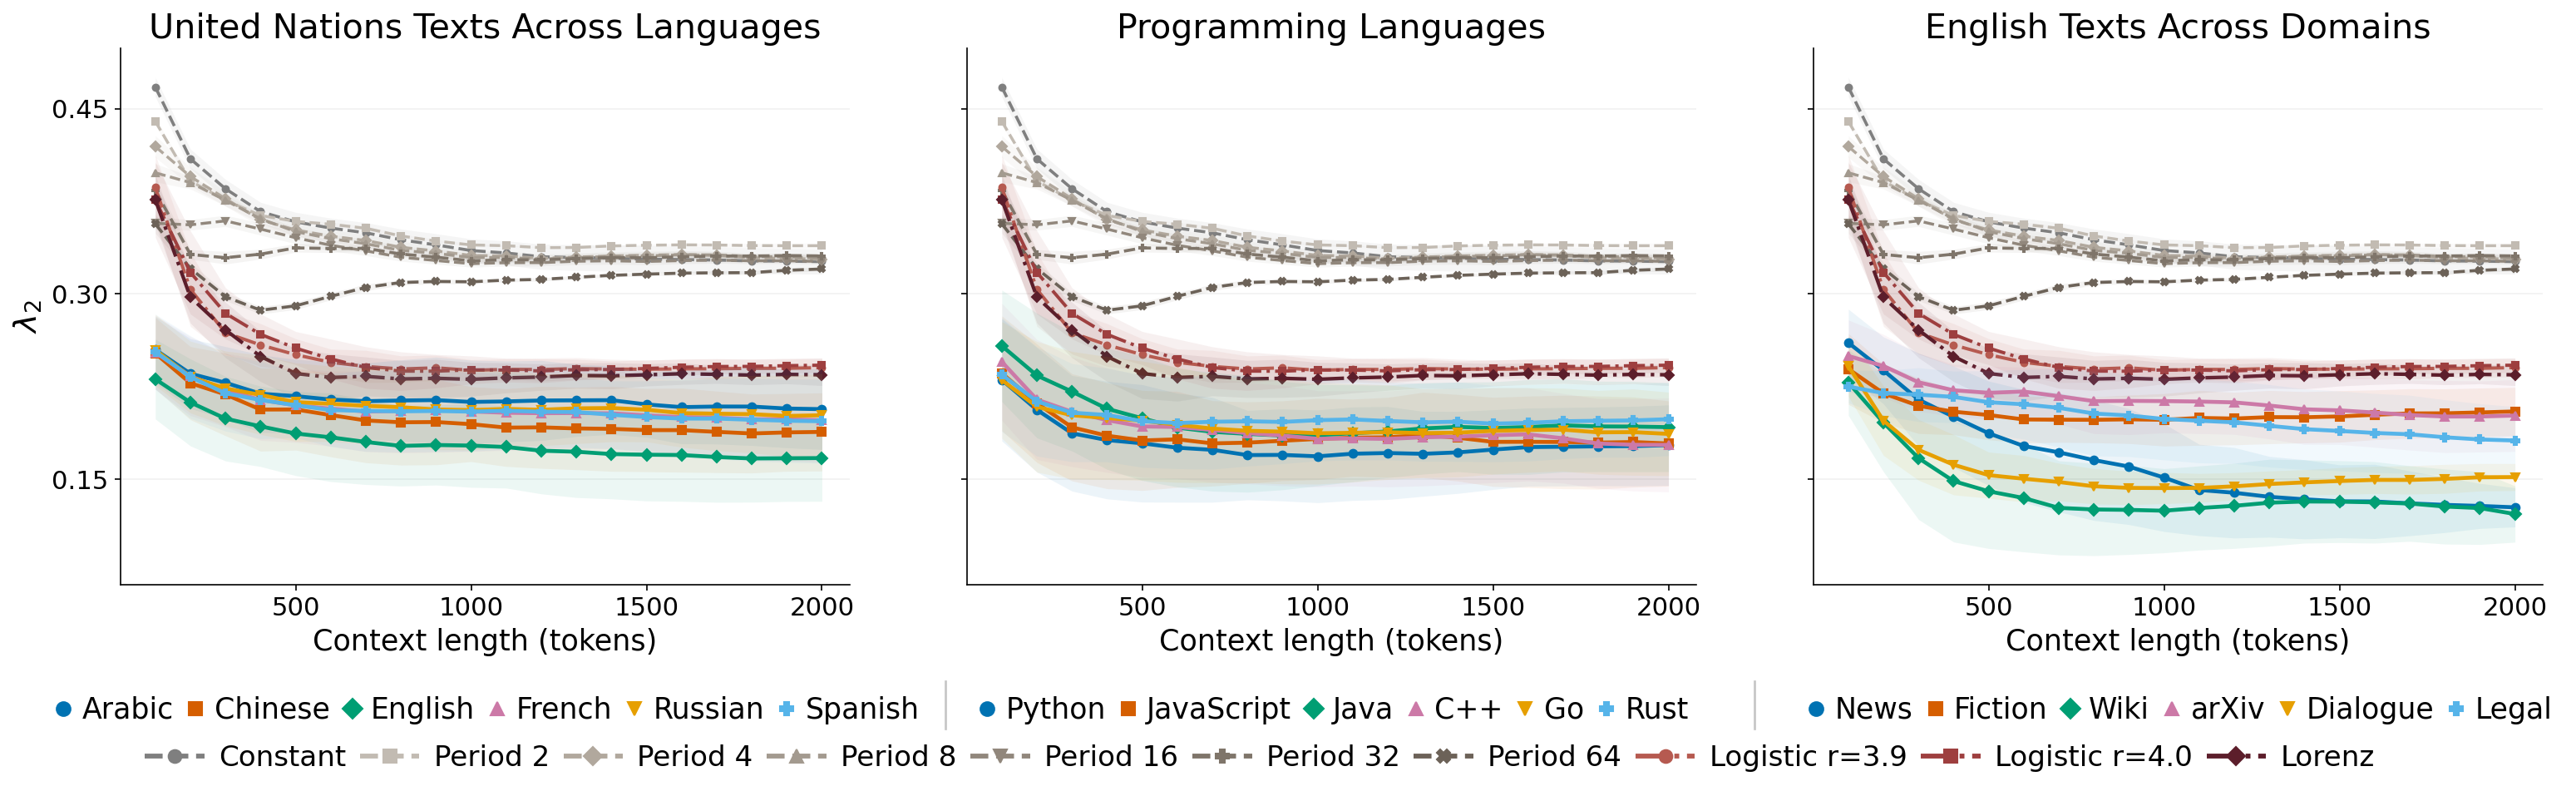

In [6]:
plot_three_panel_metric("fiedler")

Plot the high-frequency energy ratio (HFER) across context lengths.

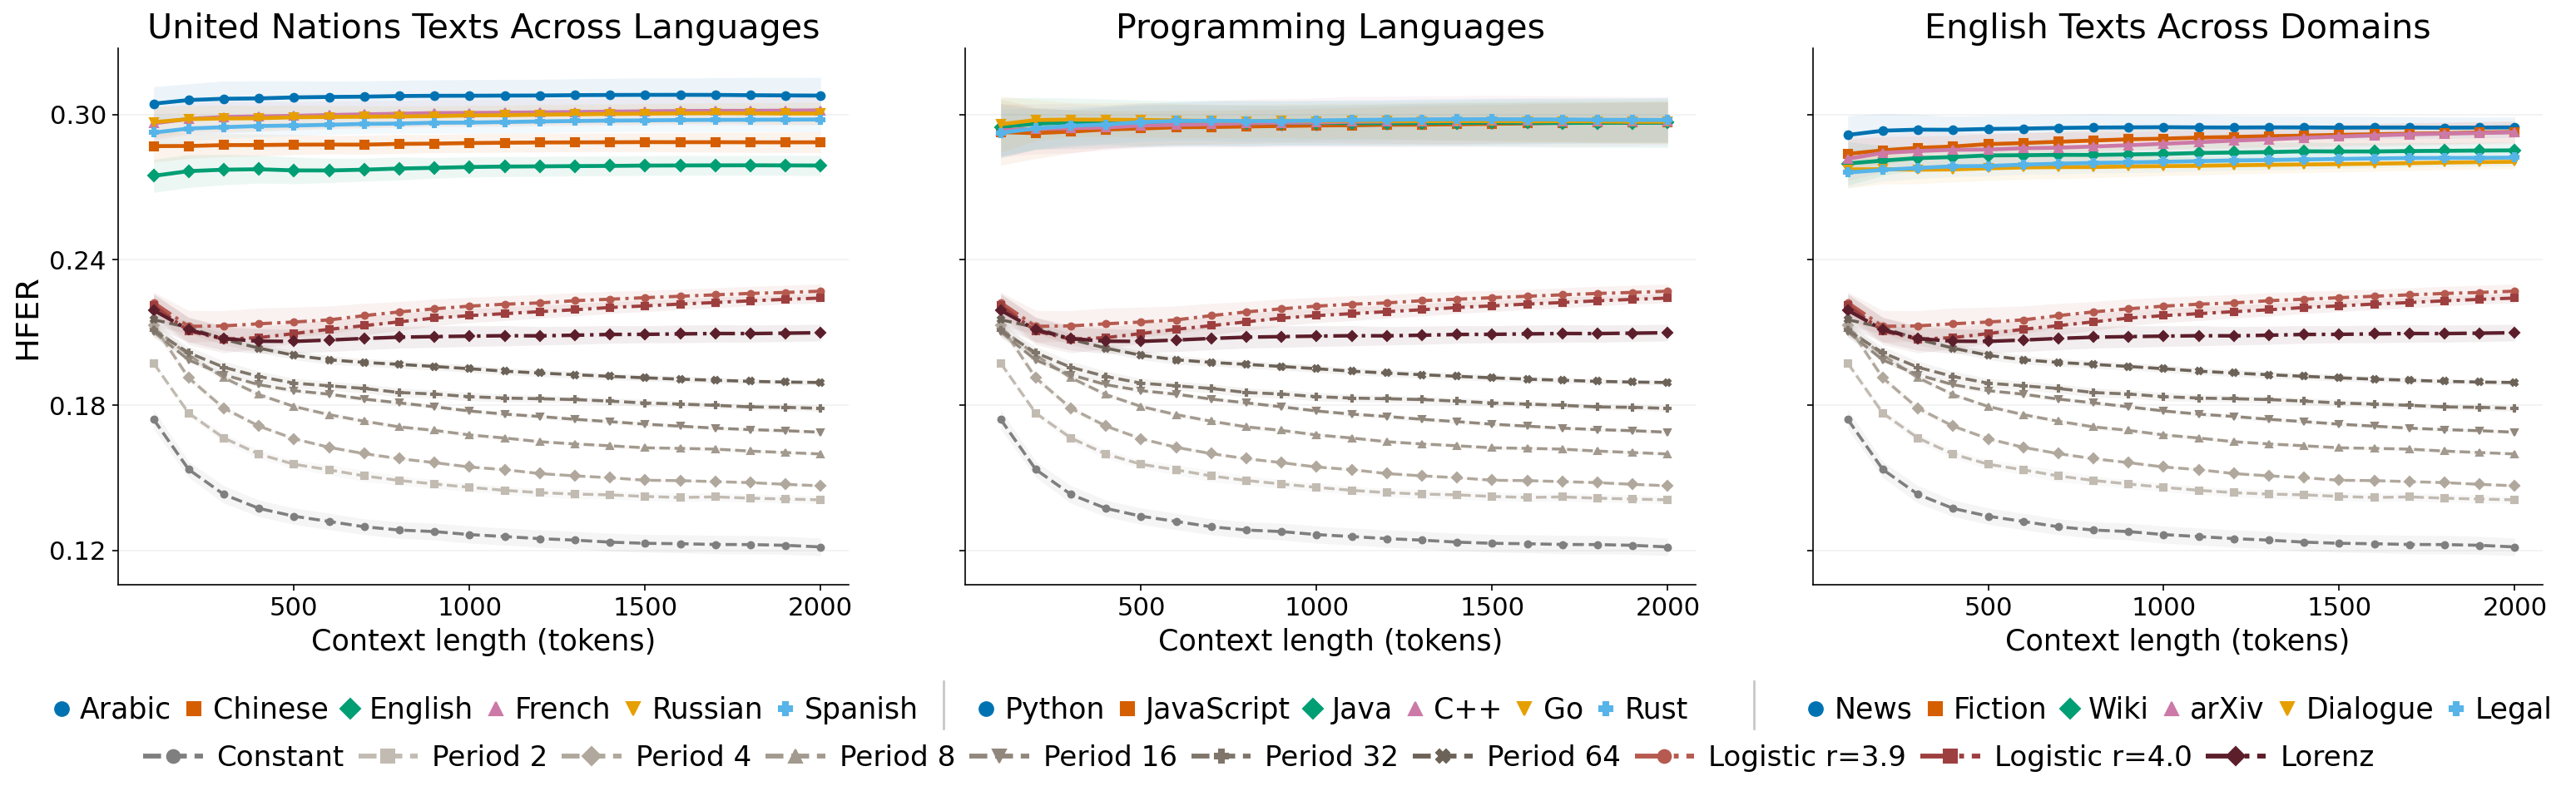

In [7]:
plot_three_panel_metric("hfer")